In [1]:
# Running locally: the CSV 'ershoufang-origin-utf8.csv' is in the same folder as this notebook.
# (In Google Colab, use: from google.colab import files; files.upload())

In [2]:
import os
assert os.path.exists('ershoufang-origin-utf8.csv'), "Put ershoufang-origin-utf8.csv next to this notebook"

In [3]:
import warnings
warnings.filterwarnings('ignore')

In [4]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm  # plain-text progress bars (no ipywidgets needed, works in VS Code)

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [5]:
sns.set_style("whitegrid")
plt.rcParams['axes.unicode_minus'] = False

print("All libraries imported and configured successfully.")

All libraries imported and configured successfully.


In [6]:
# Load dataset (on_bad_lines='skip' safely handles multiline text in mortgage records)
df = pd.read_csv('ershoufang-origin-utf8.csv', encoding='utf-8', on_bad_lines='skip')
print(f"Raw dataset shape: {df.shape}")

# 0. FIX: Villa listings ('别墅') lack the 建筑类型/梯户比例/配备电梯 fields on the source site,
#    so every column after 建筑面积 is shifted by one. Realign them before feature extraction.
villa = (df['房屋用途'] == '别墅') & (df['装修情况'] == '70年')
src = ['户型结构', '套内面积', '房屋朝向', '建筑类型', '装修情况']
dst = ['套内面积', '房屋朝向', '装修情况', '建筑结构', '产权年限']
df.loc[villa, dst] = df.loc[villa, src].values
df.loc[villa, '户型结构'] = np.nan
df.loc[villa, '建筑类型'] = '别墅'
print(f"Realigned {villa.sum()} shifted villa rows")

# 1. Strip text units and convert core columns to numeric floats
df['unit_price'] = pd.to_numeric(df['单价'].astype(str).str.replace('元/平米', '', regex=False), errors='coerce')
df['area'] = pd.to_numeric(df['建筑面积'].astype(str).str.replace('㎡', '', regex=False), errors='coerce')
df['total_price'] = pd.to_numeric(df['总价'], errors='coerce')

# 2. Extract structured numeric features from text strings
df['rooms'] = df['房屋户型'].astype(str).str.extract(r'(\d+)室', expand=False).astype(float)
df['halls'] = df['房屋户型'].astype(str).str.extract(r'(\d+)厅', expand=False).astype(float)
df['total_floors'] = df['所在楼层'].astype(str).str.extract(r'共(\d+)层', expand=False).astype(float)

# 3. Map categorical Chinese values to English for clean English charts and tables
district_map = {
    '江宁': 'Jiangning', '鼓楼': 'Gulou', '秦淮': 'Qinhuai',
    '浦口': 'Pukou', '建邺': 'Jianye', '玄武': 'Xuanwu',
    '栖霞': 'Qixia', '雨花台': 'Yuhuatai', '六合': 'Liuhe'
}
decoration_map = {
    '精装': 'Refined', '简装': 'Simple', '毛坯': 'Roughcast', '其他': 'Other'
}
building_map = {
    '板楼': 'Slab', '塔楼': 'Tower', '板塔结合': 'Slab-Tower', '平房': 'Bungalow', '别墅': 'Villa'
}
elevator_map = {
    '有': 'Yes', '无': 'No'
}

df['district'] = df['所在区域'].map(district_map).fillna('Other')
df['decoration'] = df['装修情况'].map(decoration_map).fillna('Unknown')
df['building_type'] = df['建筑类型'].map(building_map).fillna('Unknown')
df['elevator'] = df['配备电梯'].map(elevator_map).fillna('Unknown')

# 4. Drop records with missing core values and remove extreme outliers
df_clean = df.dropna(subset=['total_price', 'unit_price', 'area', '所在区域', 'rooms', 'halls']).copy()
df_clean = df_clean[
    (df_clean['total_price'] > 0) & (df_clean['total_price'] <= 3000) &
    (df_clean['area'] > 10) & (df_clean['area'] <= 500) &
    (df_clean['unit_price'] > 1000) & (df_clean['unit_price'] <= 100000)
].copy()

print(f"Cleaned dataset shape: {df_clean.shape}")
display(df_clean[['id', 'district', 'total_price', 'unit_price', 'area', 'rooms', 'halls', 'elevator']].head())

Raw dataset shape: (20432, 25)
Realigned 202 shifted villa rows
Cleaned dataset shape: (20393, 35)


,id,district,total_price,unit_price,area,rooms,halls,elevator
0,1,Qixia,399.0,32178.0,124.00,3.0,2.0,Yes
1,2,Gulou,680.0,34445.0,197.42,5.0,2.0,Yes
2,3,Xuanwu,152.0,29682.0,51.21,2.0,1.0,No
3,4,Qixia,230.0,25556.0,90.00,2.0,2.0,No
4,5,Yuhuatai,315.0,39019.0,80.73,2.0,1.0,Yes


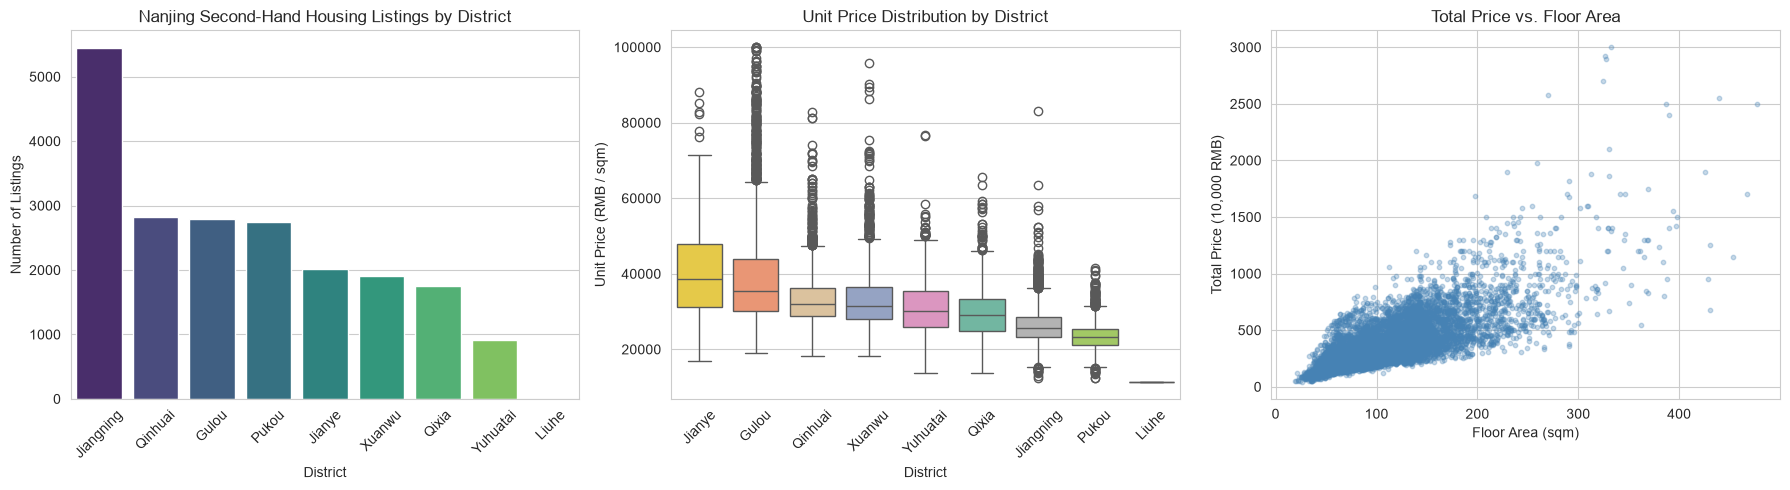

In [7]:
# ==============================================================================
# CELL 3: Exploratory Data Analysis (EDA)
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Listing Count by District
district_counts = df_clean['district'].value_counts()
sns.barplot(x=district_counts.index, y=district_counts.values, hue=district_counts.index,
            ax=axes[0], palette='viridis', legend=False)
axes[0].set_title('Nanjing Second-Hand Housing Listings by District')
axes[0].set_xlabel('District')
axes[0].set_ylabel('Number of Listings')
axes[0].tick_params(axis='x', rotation=45)

# Plot 2: Unit Price Distribution by District (Boxplot sorted by median)
order = df_clean.groupby('district')['unit_price'].median().sort_values(ascending=False).index
sns.boxplot(data=df_clean, x='district', y='unit_price', hue='district', order=order,
            ax=axes[1], palette='Set2', legend=False)
axes[1].set_title('Unit Price Distribution by District')
axes[1].set_xlabel('District')
axes[1].set_ylabel('Unit Price (RMB / sqm)')
axes[1].tick_params(axis='x', rotation=45)

# Plot 3: Total Price vs. Area Scatter Plot
axes[2].scatter(df_clean['area'], df_clean['total_price'], alpha=0.3, s=10, color='steelblue')
axes[2].set_title('Total Price vs. Floor Area')
axes[2].set_xlabel('Floor Area (sqm)')
axes[2].set_ylabel('Total Price (10,000 RMB)')

plt.tight_layout()
plt.show()

Elbow method (fitting K-Means):   0%|          | 0/9 [00:00<?, ?K/s]

Elbow method (fitting K-Means):  33%|███▎      | 3/9 [00:00<00:00, 23.82K/s]

Elbow method (fitting K-Means):  67%|██████▋   | 6/9 [00:00<00:00, 18.40K/s]

Elbow method (fitting K-Means):  89%|████████▉ | 8/9 [00:00<00:00, 15.07K/s]

Elbow method (fitting K-Means): 100%|██████████| 9/9 [00:00<00:00, 14.91K/s]

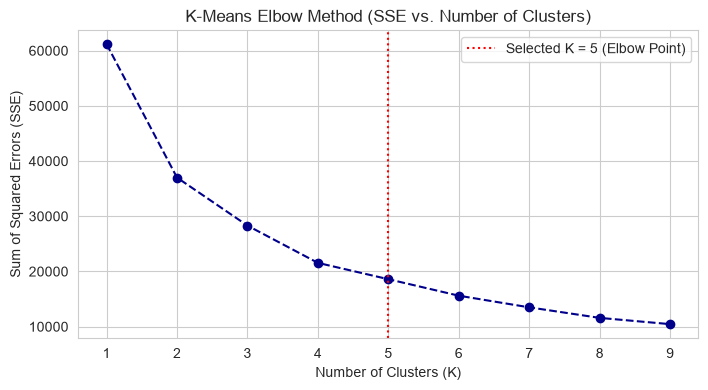

In [8]:
# ==============================================================================
# CELL 4: Feature Standardization & Elbow Method for K-Means
# ==============================================================================
cluster_features = ['total_price', 'unit_price', 'area']

# Standardize features (mean=0, std=1) so unit_price (~30,000) does not dominate area (~90)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_clean[cluster_features])

# Evaluate Sum of Squared Errors (SSE / Inertia) across K = 1 to 9
sse = []
k_range = range(1, 10)
for k in tqdm(k_range, desc='Elbow method (fitting K-Means)', unit='K'):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    sse.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(k_range, sse, marker='o', linestyle='--', color='darkblue')
plt.axvline(x=5, color='red', linestyle=':', label='Selected K = 5 (Elbow Point)')
plt.title('K-Means Elbow Method (SSE vs. Number of Clusters)')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Sum of Squared Errors (SSE)')
plt.legend()
plt.show()

=== K-Means Clustering Summary Table (K = 5) ===


,Listing_Count,Avg_Total_Price_10k_RMB,Avg_Unit_Price_RMB_sqm,Avg_Area_sqm
Cluster,,,,
0,3733,443.7,32312.8,140.6
1,8003,196.2,30784.7,63.3
2,6537,248.6,24321.9,102.8
3,1530,494.3,55304.8,91.2
4,590,951.8,42411.8,231.0


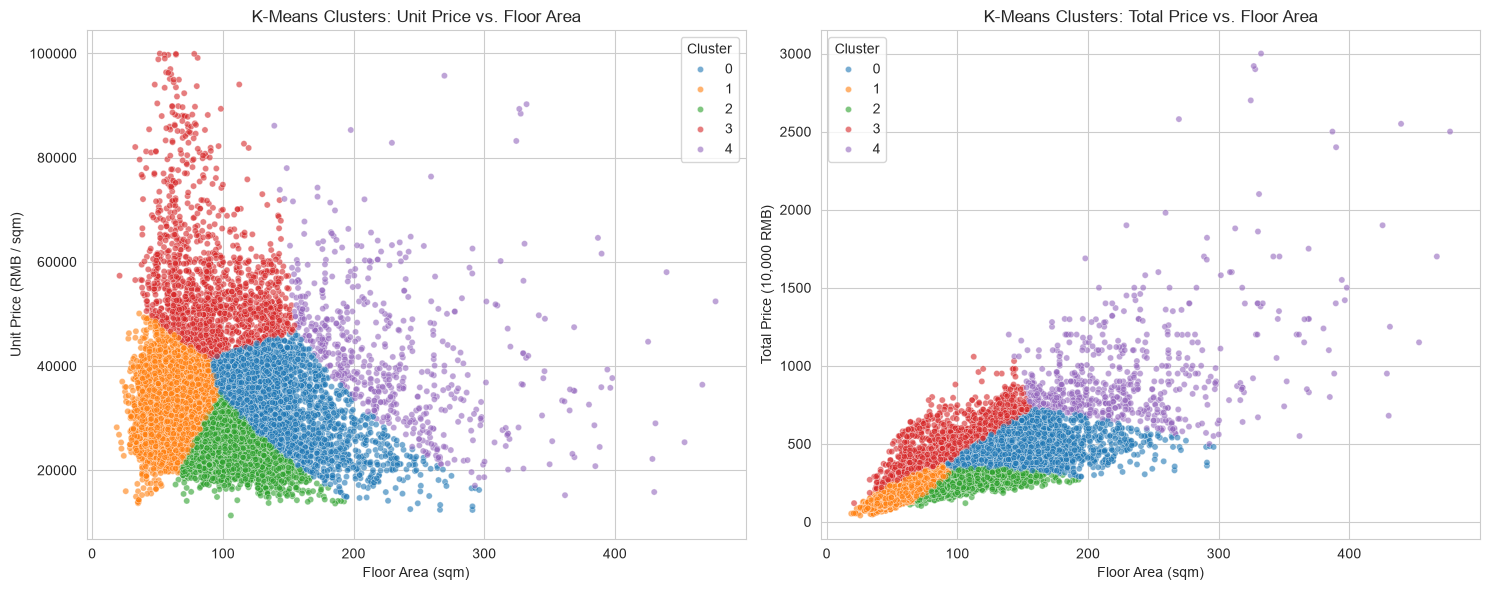

In [9]:
# ==============================================================================
# CELL 5: K-Means Clustering (K=5) & Market Segmentation Analysis
# ==============================================================================
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df_clean['Cluster'] = kmeans.fit_predict(X_scaled)

# Summarize cluster centroids in original physical units
cluster_summary = df_clean.groupby('Cluster').agg(
    Listing_Count=('id', 'count'),
    Avg_Total_Price_10k_RMB=('total_price', 'mean'),
    Avg_Unit_Price_RMB_sqm=('unit_price', 'mean'),
    Avg_Area_sqm=('area', 'mean')
).round(1)

print("=== K-Means Clustering Summary Table (K = 5) ===")
display(cluster_summary)

# Scatter plots showing the 5 housing segments
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.scatterplot(
    data=df_clean, x='area', y='unit_price', hue='Cluster',
    palette='tab10', alpha=0.6, s=20, ax=axes[0]
)
axes[0].set_title('K-Means Clusters: Unit Price vs. Floor Area')
axes[0].set_xlabel('Floor Area (sqm)')
axes[0].set_ylabel('Unit Price (RMB / sqm)')

sns.scatterplot(
    data=df_clean, x='area', y='total_price', hue='Cluster',
    palette='tab10', alpha=0.6, s=20, ax=axes[1]
)
axes[1].set_title('K-Means Clusters: Total Price vs. Floor Area')
axes[1].set_xlabel('Floor Area (sqm)')
axes[1].set_ylabel('Total Price (10,000 RMB)')

plt.tight_layout()
plt.show()

In [10]:
# ==============================================================================
# CELL 6 (UPGRADED): Feature Engineering, Target Encoding & Model Comparison
# ==============================================================================
from sklearn.ensemble import GradientBoostingRegressor

# 1. Extract additional domain features from raw columns
df_clean['baths'] = df_clean['房屋户型'].astype(str).str.extract(r'(\d+)卫', expand=False).astype(float).fillna(1)
df_clean['total_floors'] = df_clean['total_floors'].fillna(df_clean['total_floors'].median())

floor_map = {'低楼层': 'Low', '中楼层': 'Mid', '高楼层': 'High'}
df_clean['floor_tier'] = df_clean['所在楼层'].astype(str).str.extract(r'^(低楼层|中楼层|高楼层)', expand=False).map(floor_map).fillna('Unknown')

# Ratios and domain indicators
df_clean['area_per_room'] = df_clean['area'] / (df_clean['rooms'] + 1)
df_clean['total_rooms'] = df_clean['rooms'] + df_clean['halls'] + df_clean['baths']
df_clean['is_south'] = df_clean['房屋朝向'].astype(str).str.contains('南').astype(int)

# Property age proxy (Listing Year - Last Transaction Year); '暂无数据' (no data) becomes NaN -> -1
listing_yr = pd.to_datetime(df_clean['挂牌时间'], format='%Y-%m-%d', errors='coerce').dt.year
last_tx_yr = pd.to_datetime(df_clean['上次交易'], format='%Y-%m-%d', errors='coerce').dt.year
df_clean['years_since_last_tx'] = (listing_yr - last_tx_yr).fillna(-1)

# Map additional categorical features to English
tenure_map = {'满五年': 'Over_5_Yrs', '满两年': '2_to_5_Yrs', '未满两年': 'Under_2_Yrs'}
structure_map = {'钢混结构': 'Steel_Concrete', '砖混结构': 'Brick_Concrete', '混合结构': 'Mixed'}
df_clean['tenure'] = df_clean['房屋年限'].map(tenure_map).fillna('Unknown')
df_clean['structure'] = df_clean['建筑结构'].map(structure_map).fillna('Other')

num_cols = [
    'area', 'rooms', 'halls', 'baths', 'total_floors',
    'area_per_room', 'total_rooms', 'is_south', 'years_since_last_tx'
]
cat_cols = ['district', 'decoration', 'building_type', 'elevator', 'floor_tier', 'tenure', 'structure']

X_base = pd.get_dummies(df_clean[num_cols + cat_cols], drop_first=True)
y = df_clean['total_price']

# 2. 80/20 Train-Test Split (preserving indices for leak-free target encoding)
X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X_base, y, df_clean.index, test_size=0.2, random_state=42
)

# 3. Leak-Free Smoothed Target Encoding for Residential Compound ('小区名称')
# Computed strictly on X_train so test data never leaks into training features
train_subset = df_clean.loc[idx_train]
test_subset = df_clean.loc[idx_test]

global_unit_mean = train_subset['unit_price'].mean()
comm_stats = train_subset.groupby('小区名称')['unit_price'].agg(['mean', 'count'])
smoothing_weight = 5  # Bayesian smoothing prevents overfitting on rare compounds
comm_encoded_map = (comm_stats['count'] * comm_stats['mean'] + smoothing_weight * global_unit_mean) / (comm_stats['count'] + smoothing_weight)

X_train = X_train.copy()
X_test = X_test.copy()

X_train['compound_est_unit_price'] = train_subset['小区名称'].map(comm_encoded_map).fillna(global_unit_mean)
X_test['compound_est_unit_price'] = test_subset['小区名称'].map(comm_encoded_map).fillna(global_unit_mean)

# Interaction feature: Compound baseline unit price * Floor area
X_train['compound_baseline_total'] = (X_train['compound_est_unit_price'] * X_train['area']) / 10000.0
X_test['compound_baseline_total'] = (X_test['compound_est_unit_price'] * X_test['area']) / 10000.0

# 4. Train and Evaluate All 3 Models
models = {
    'Decision Tree (Baseline)': DecisionTreeRegressor(max_depth=10, min_samples_leaf=15, random_state=42),
    'Random Forest (Upgraded)': RandomForestRegressor(n_estimators=300, max_depth=18, min_samples_leaf=3, random_state=42, n_jobs=-1),
    'Gradient Boosting (Upgraded)': GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=6, random_state=42)
}

results = []
predictions = {}

progress = tqdm(models.items(), total=len(models), desc='Training models', unit='model')
for name, model in progress:
    progress.set_postfix_str(f'now: {name}')
    start = time.time()
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    predictions[name] = preds
    progress.write(f'  ✓ {name} trained in {time.time() - start:.1f}s')
    results.append({
        'Model': name,
        'R2_Score': r2_score(y_test, preds),
        'MAE (10k RMB)': mean_absolute_error(y_test, preds),
        'RMSE (10k RMB)': np.sqrt(mean_squared_error(y_test, preds))
    })
progress.set_postfix_str('done')
progress.close()

comparison_df = pd.DataFrame(results).round(4)
print("=== Upgraded Regression Model Performance Comparison ===")
display(comparison_df)

Training models:   0%|          | 0/3 [00:00<?, ?model/s]

Training models:   0%|          | 0/3 [00:00<?, ?model/s, now: Decision Tree (Baseline)]

Training models:   0%|          | 0/3 [00:00<?, ?model/s, now: Decision Tree (Baseline)]

Training models:   0%|          | 0/3 [00:00<?, ?model/s, now: Random Forest (Upgraded)]

  ✓ Decision Tree (Baseline) trained in 0.1s


Training models:   0%|          | 0/3 [00:01<?, ?model/s, now: Random Forest (Upgraded)]

... (4 outputs left out)

Training models: 100%|██████████| 3/3 [00:13<00:00,  5.34s/model, now: Gradient Boosting (Upgraded)]

Training models: 100%|██████████| 3/3 [00:13<00:00,  4.45s/model, now: Gradient Boosting (Upgraded)]

  ✓ Gradient Boosting (Upgraded) trained in 11.6s
=== Upgraded Regression Model Performance Comparison ===


,Model,R2_Score,MAE (10k RMB),RMSE (10k RMB)
0,Decision Tree (Baseline),0.8735,31.0688,64.4312
1,Random Forest (Upgraded),0.8957,27.8584,58.5006
2,Gradient Boosting (Upgraded),0.9093,26.9846,54.5472


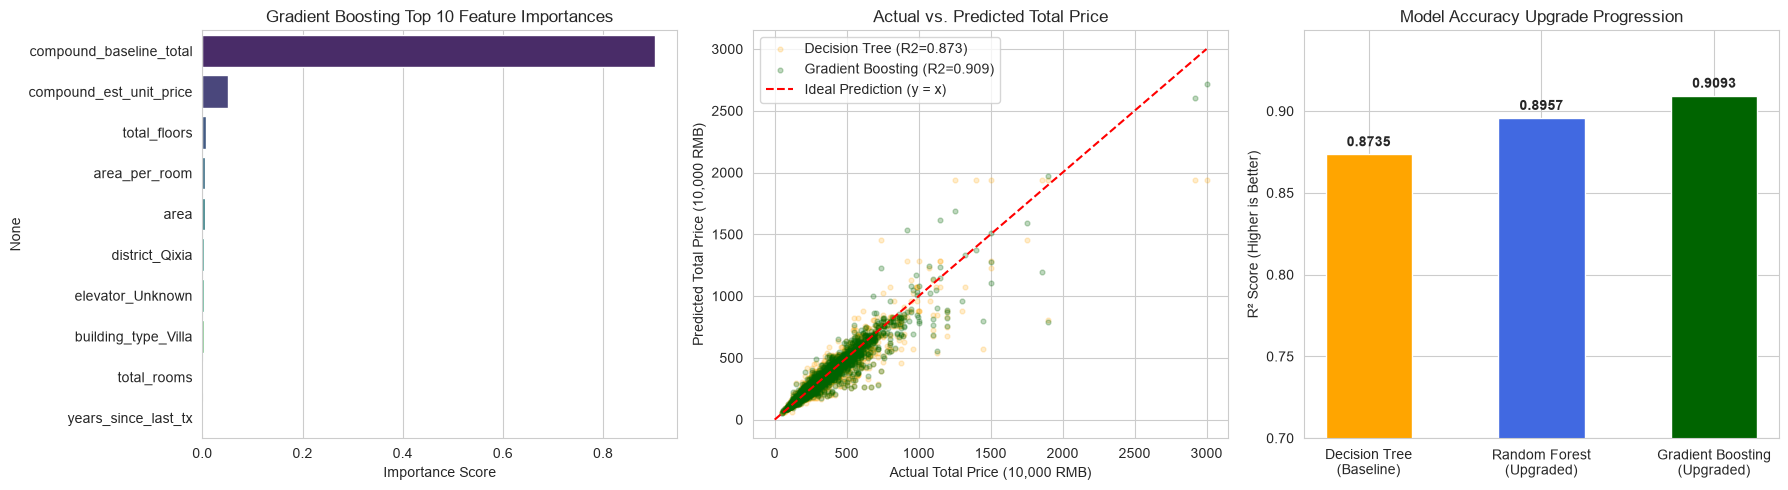

In [11]:
# ==============================================================================
# CELL 7 (UPGRADED): Visual Comparison & Feature Importance
# ==============================================================================
gb_model = models['Gradient Boosting (Upgraded)']
gb_pred = predictions['Gradient Boosting (Upgraded)']
dt_pred = predictions['Decision Tree (Baseline)']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Top 10 Feature Importances (Gradient Boosting)
gb_importances = pd.Series(gb_model.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(10)
sns.barplot(x=gb_importances.values, y=gb_importances.index, hue=gb_importances.index,
            ax=axes[0], palette='viridis', legend=False)
axes[0].set_title('Gradient Boosting Top 10 Feature Importances')
axes[0].set_xlabel('Importance Score')

# Plot 2: Actual vs. Predicted Overlay (Baseline DT vs. Upgraded GBDT)
axes[1].scatter(y_test, dt_pred, alpha=0.2, s=12, color='orange', label=f"Decision Tree (R2={r2_score(y_test, dt_pred):.3f})")
axes[1].scatter(y_test, gb_pred, alpha=0.25, s=12, color='darkgreen', label=f"Gradient Boosting (R2={r2_score(y_test, gb_pred):.3f})")
lim = max(y_test.max(), dt_pred.max(), gb_pred.max())
axes[1].plot([0, lim], [0, lim], 'r--', lw=1.5, label='Ideal Prediction (y = x)')
axes[1].set_title('Actual vs. Predicted Total Price')
axes[1].set_xlabel('Actual Total Price (10,000 RMB)')
axes[1].set_ylabel('Predicted Total Price (10,000 RMB)')
axes[1].legend()

# Plot 3: R2 Accuracy Progression Bar Chart
model_names = ['Decision Tree\n(Baseline)', 'Random Forest\n(Upgraded)', 'Gradient Boosting\n(Upgraded)']
r2_scores = comparison_df['R2_Score'].values
bars = axes[2].bar(model_names, r2_scores, color=['orange', 'royalblue', 'darkgreen'], width=0.5)
axes[2].set_ylim(min(0.70, r2_scores.min() - 0.05), min(1.0, r2_scores.max() + 0.04))
axes[2].set_ylabel('R² Score (Higher is Better)')
axes[2].set_title('Model Accuracy Upgrade Progression')
for bar, score in zip(bars, r2_scores):
    axes[2].text(bar.get_x() + bar.get_width()/2, score + 0.005, f"{score:.4f}", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

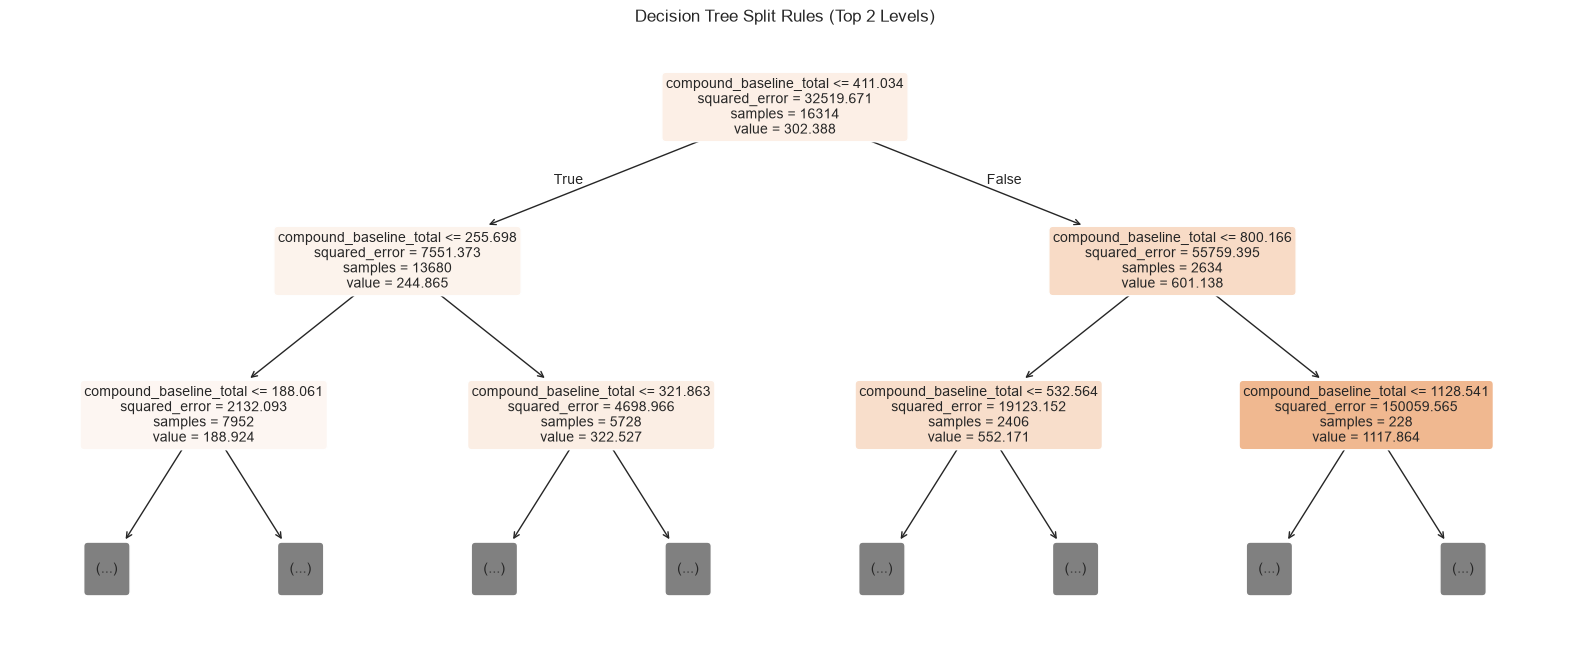

In [12]:
# ==============================================================================
# CELL 8: Visualize Top 2 Levels of the Decision Tree (Interpretability)
# ==============================================================================
dt_model = models['Decision Tree (Baseline)']

plt.figure(figsize=(20, 8))
plot_tree(
    dt_model,
    max_depth=2,
    feature_names=X_train.columns.tolist(),
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title('Decision Tree Split Rules (Top 2 Levels)')
plt.show()

# Walkthrough: from raw data to prediction

This section shows **how the data changes**, **how each model learns**, and **how a model predicts** one house.

We follow one **example house from the test set** the whole way through. The models never saw it during training.

## Part 1: How the data changes

### 1a. Data funnel: how many rows survive each step

,Step,Rows,Removed / Note
0,1. Raw CSV rows,20432,202 villa rows realigned (columns were shifted)
1,2. Drop rows missing price / area / layout,20404,"-28 rows (garages, missing values)"
2,3. Remove extreme outliers,20393,"-11 rows (price > 30M, area > 500 sqm, ...)"
3,4a. Training set (80%),16314,models learn from these
4,4b. Test set (20%),4079,models are graded on these (never seen in trai...


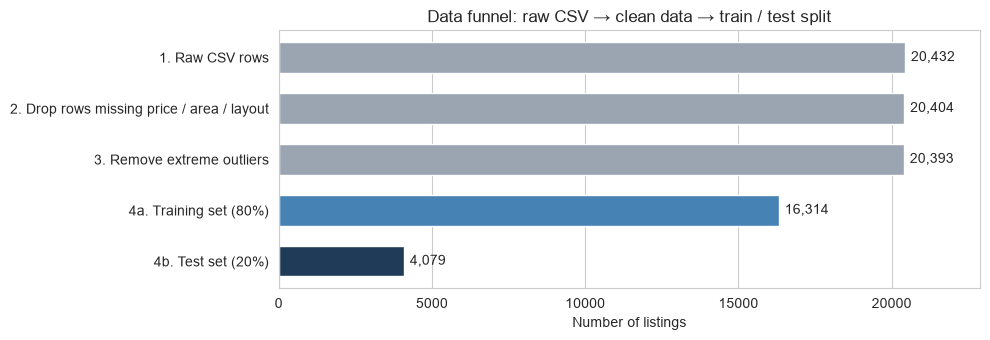

In [13]:
# ==============================================================================
# WALKTHROUGH 1a: Row count at every data-processing step
# ==============================================================================
core_cols = ['total_price', 'unit_price', 'area', '所在区域', 'rooms', 'halls']
after_dropna = len(df.dropna(subset=core_cols))

funnel = pd.DataFrame({
    'Step': [
        '1. Raw CSV rows',
        '2. Drop rows missing price / area / layout',
        '3. Remove extreme outliers',
        '4a. Training set (80%)',
        '4b. Test set (20%)',
    ],
    'Rows': [len(df), after_dropna, len(df_clean), len(X_train), len(X_test)],
})
funnel['Removed / Note'] = [
    f'{villa.sum()} villa rows realigned (columns were shifted)',
    f'-{len(df) - after_dropna} rows (garages, missing values)',
    f'-{after_dropna - len(df_clean)} rows (price > 30M, area > 500 sqm, ...)',
    'models learn from these',
    'models are graded on these (never seen in training)',
]
display(funnel)

fig, ax = plt.subplots(figsize=(10, 3.5))
colors = ['#9aa5b1'] * 3 + ['steelblue', '#1f3b57']
bars = ax.barh(funnel['Step'][::-1], funnel['Rows'][::-1], color=colors[::-1], height=0.6)
for bar, n in zip(bars, funnel['Rows'][::-1]):
    ax.text(bar.get_width() + 200, bar.get_y() + bar.get_height() / 2, f'{n:,}', va='center')
ax.set_xlim(0, len(df) * 1.12)
ax.set_xlabel('Number of listings')
ax.set_title('Data funnel: raw CSV → clean data → train / test split')
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

### 1b. One house: raw text → clean numbers → model input
The CSV stores everything as text (`'30052元/平米'`, `'4室2厅1厨3卫'`, `'中楼层 (共4层)'`). The models only understand numbers, so each field is converted.

In [14]:
# ==============================================================================
# WALKTHROUGH 1b: Follow ONE house through every transformation
# ==============================================================================
ex = idx_test[0]                  # example house (from the test set)
r = df_clean.loc[ex]

steps = [
    ('Compound name',  r['小区名称'], f"compound_est_unit_price = {X_test.loc[ex, 'compound_est_unit_price']:,.0f} RMB/sqm (avg of similar listings)"),
    ('District',       r['所在区域'], f"district = {r['district']}  → one-hot column district_{r['district']} = 1"),
    ('Total price',    r['总价'],     f"total_price = {r['total_price']:.0f}  (10,000 RMB)  ← this is what we predict"),
    ('Unit price',     r['单价'],     f"unit_price = {r['unit_price']:,.0f}"),
    ('Floor area',     r['建筑面积'], f"area = {r['area']}"),
    ('Layout',         r['房屋户型'], f"rooms = {r['rooms']:.0f}, halls = {r['halls']:.0f}, baths = {r['baths']:.0f}"),
    ('Floor',          r['所在楼层'], f"floor_tier = {r['floor_tier']}, total_floors = {r['total_floors']:.0f}"),
    ('Orientation',    r['房屋朝向'], f"is_south = {r['is_south']}"),
    ('Decoration',     r['装修情况'], f"decoration = {r['decoration']}"),
    ('Elevator',       r['配备电梯'], f"elevator = {r['elevator']}"),
    ('Listed / last sold', f"{r['挂牌时间']} / {r['上次交易']}", f"years_since_last_tx = {r['years_since_last_tx']:.0f}"),
]
print(f"Example house id = {r['id']}\n")
display(pd.DataFrame(steps, columns=['Field', 'Raw text in CSV', 'After cleaning / feature engineering']))

# What the model actually receives: one row of numbers
x_ex = X_test.loc[[ex]].astype(float)
nonzero = x_ex.T[x_ex.T.iloc[:, 0] != 0]
nonzero.columns = ['value']
print(f"\nThe model receives {X_train.shape[1]} numbers for every house. "
      f"For this house {len(nonzero)} of them are non-zero (all others are 0):")
display(nonzero.round(2))

Example house id = 10169



,Field,Raw text in CSV,After cleaning / feature engineering
0,Compound name,威尼斯水城第三街区,"compound_est_unit_price = 22,216 RMB/sqm (avg ..."
1,District,浦口,district = Pukou → one-hot column district_Pu...
2,Total price,265.0,"total_price = 265 (10,000 RMB) ← this is wha..."
3,Unit price,20307元/平米,"unit_price = 20,307"
4,Floor area,130.5㎡,area = 130.5
5,Layout,3室2厅1厨2卫,"rooms = 3, halls = 2, baths = 2"
6,Floor,中楼层 (共16层),"floor_tier = Mid, total_floors = 16"
7,Orientation,南 北,is_south = 1
8,Decoration,其他,decoration = Other
9,Elevator,有,elevator = Yes



The model receives 37 numbers for every house. For this house 17 of them are non-zero (all others are 0):


,value
area,130.50
rooms,3.00
halls,2.00
baths,2.00
total_floors,16.00
area_per_room,32.62
total_rooms,7.00
is_south,1.00
years_since_last_tx,-1.00
district_Pukou,1.00


## Part 2: How the models learn

**Training error** (dashed) = error on houses the model has already seen.
**Test error** (solid) = error on new houses, which is the score that matters.
When training error keeps falling but test error stops improving (or rises), the model is **memorising instead of learning** (*overfitting*).

Decision Tree: trying depths 1-20:   0%|          | 0/20 [00:00<?, ?it/s]

Decision Tree: trying depths 1-20:  25%|██▌       | 5/20 [00:00<00:00, 38.25it/s]

Decision Tree: trying depths 1-20:  45%|████▌     | 9/20 [00:00<00:00, 25.00it/s]

Decision Tree: trying depths 1-20:  60%|██████    | 12/20 [00:00<00:00, 20.12it/s]

Decision Tree: trying depths 1-20:  75%|███████▌  | 15/20 [00:00<00:00, 17.18it/s]

Decision Tree: trying depths 1-20:  85%|████████▌ | 17/20 [00:00<00:00, 16.03it/s]

Decision Tree: trying depths 1-20:  95%|█████████▌| 19/20 [00:01<00:00, 15.40it/s]

Decision Tree: trying depths 1-20: 100%|██████████| 20/20 [00:01<00:00, 17.66it/s]

Random Forest: 300 trees:   0%|          | 0/300 [00:00<?, ?it/s]

Random Forest: 300 trees:  62%|██████▏   | 187/300 [00:00<00:00, 1821.08it/s]

Random Forest: 300 trees: 100%|██████████| 300/300 [00:00<00:00, 1838.07it/s]

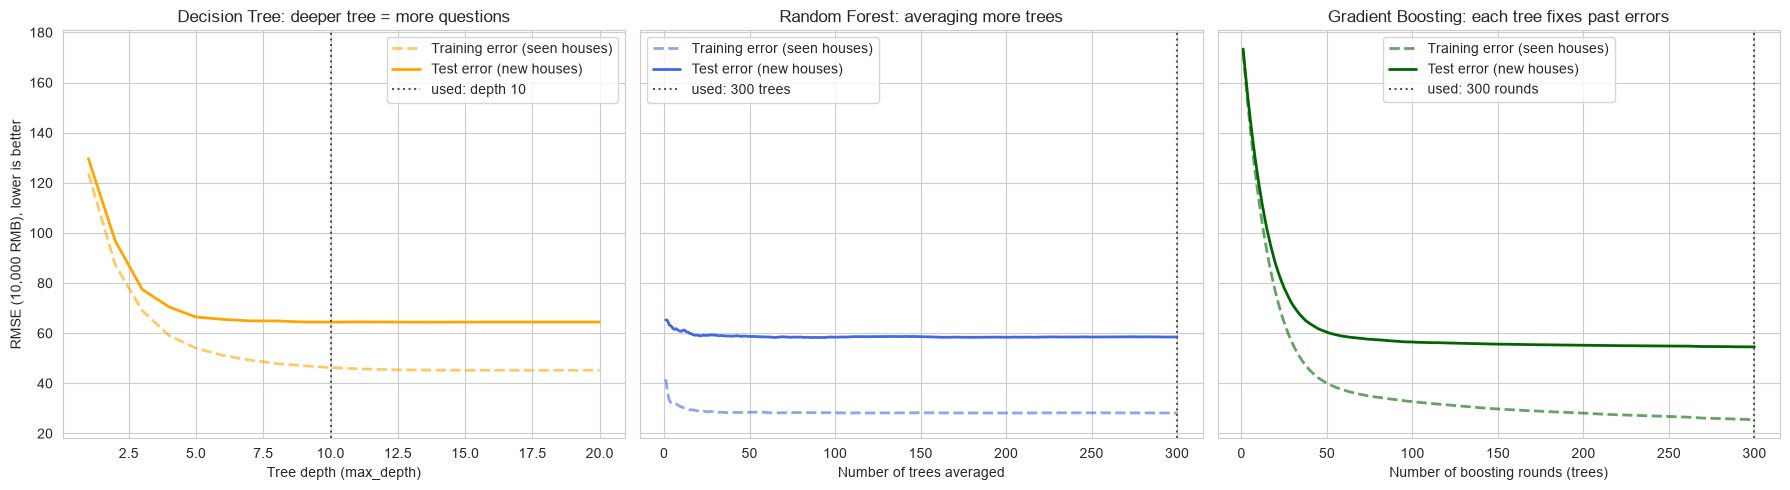

Final test RMSE → Decision Tree: 64.4   Random Forest: 58.5   Gradient Boosting: 54.5


In [15]:
# ==============================================================================
# WALKTHROUGH 2: Learning curves for all three models
# ==============================================================================
def rmse(a, b):
    return np.sqrt(mean_squared_error(a, b))

rf_model = models['Random Forest (Upgraded)']
X_train_np = X_train.to_numpy(dtype=np.float32)
X_test_np = X_test.to_numpy(dtype=np.float32)

# Decision Tree: retrain with deeper and deeper trees
depths = list(range(1, 21))
dt_train_err, dt_test_err = [], []
for d in tqdm(depths, desc='Decision Tree: trying depths 1-20'):
    m = DecisionTreeRegressor(max_depth=d, min_samples_leaf=15, random_state=42).fit(X_train, y_train)
    dt_train_err.append(rmse(y_train, m.predict(X_train)))
    dt_test_err.append(rmse(y_test, m.predict(X_test)))

# Random Forest: average the first 1, 2, ..., 300 trees
rf_tree_test = np.array([t.predict(X_test_np) for t in tqdm(rf_model.estimators_, desc='Random Forest: 300 trees')])
rf_tree_train = np.array([t.predict(X_train_np) for t in rf_model.estimators_])
n_trees = np.arange(1, len(rf_model.estimators_) + 1)[:, None]
rf_test_err = [rmse(y_test, p) for p in np.cumsum(rf_tree_test, axis=0) / n_trees]
rf_train_err = [rmse(y_train, p) for p in np.cumsum(rf_tree_train, axis=0) / n_trees]

# Gradient Boosting: prediction after each of the 300 boosting rounds
gb_train_err = [rmse(y_train, p) for p in gb_model.staged_predict(X_train)]
gb_test_err = [rmse(y_test, p) for p in gb_model.staged_predict(X_test)]

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
curves = [
    (axes[0], depths, dt_train_err, dt_test_err, 'orange', 'Decision Tree: deeper tree = more questions', 'Tree depth (max_depth)', 10, 'used: depth 10'),
    (axes[1], range(1, 301), rf_train_err, rf_test_err, 'royalblue', 'Random Forest: averaging more trees', 'Number of trees averaged', 300, 'used: 300 trees'),
    (axes[2], range(1, 301), gb_train_err, gb_test_err, 'darkgreen', 'Gradient Boosting: each tree fixes past errors', 'Number of boosting rounds (trees)', 300, 'used: 300 rounds'),
]
for ax, x, tr, te, color, title, xlabel, used, used_label in curves:
    ax.plot(x, tr, '--', color=color, lw=2, alpha=0.6, label='Training error (seen houses)')
    ax.plot(x, te, '-', color=color, lw=2, label='Test error (new houses)')
    ax.axvline(used, color='#555', ls=':', lw=1.5, label=used_label)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.legend()
axes[0].set_ylabel('RMSE (10,000 RMB), lower is better')
plt.tight_layout()
plt.show()

print(f"Final test RMSE → Decision Tree: {dt_test_err[9]:.1f}   Random Forest: {rf_test_err[-1]:.1f}   Gradient Boosting: {gb_test_err[-1]:.1f}")

## Part 3: How a model predicts

### 3a. Decision Tree: the house answers a series of yes/no questions

In [16]:
# ==============================================================================
# WALKTHROUGH 3a: Trace the example house through the Decision Tree
# ==============================================================================
tree_ = dt_model.tree_
feature_names = X_train.columns
path = dt_model.decision_path(x_ex).indices

print(f"Example house: {r['district']}, {r['area']} sqm, {r['rooms']:.0f} rooms  |  actual price = {r['total_price']:.0f} (10k RMB)\n")
for step, node in enumerate(path, start=1):
    if tree_.children_left[node] == -1:   # leaf node
        print(f"  LEAF → reached a group of {tree_.n_node_samples[node]} similar training houses.")
        print(f"         Their average price = {tree_.value[node][0][0]:.1f}  →  that is the PREDICTION.")
    else:
        name = feature_names[tree_.feature[node]]
        thr = tree_.threshold[node]
        val = float(x_ex.iloc[0][name])
        answer = 'YES → go left' if val <= thr else 'NO  → go right'
        print(f"  Q{step:>2}: Is {name} ≤ {thr:,.2f}?   (this house: {val:,.2f})   {answer}")

print(f"\nDecision Tree predicts {dt_model.predict(x_ex)[0]:.1f}  vs  actual {r['total_price']:.0f}")

Example house: Pukou, 130.5 sqm, 3 rooms  |  actual price = 265 (10k RMB)

  Q 1: Is compound_baseline_total ≤ 411.03?   (this house: 289.92)   YES → go left
  Q 2: Is compound_baseline_total ≤ 255.70?   (this house: 289.92)   NO  → go right
  Q 3: Is compound_baseline_total ≤ 321.86?   (this house: 289.92)   YES → go left
  Q 4: Is compound_est_unit_price ≤ 32,022.07?   (this house: 22,216.47)   YES → go left
  Q 5: Is compound_baseline_total ≤ 287.88?   (this house: 289.92)   NO  → go right
  Q 6: Is compound_est_unit_price ≤ 29,862.95?   (this house: 22,216.47)   YES → go left
  Q 7: Is compound_baseline_total ≤ 296.01?   (this house: 289.92)   YES → go left
  Q 8: Is elevator_Yes ≤ 0.50?   (this house: 1.00)   NO  → go right
  Q 9: Is floor_tier_Mid ≤ 0.50?   (this house: 1.00)   NO  → go right
  Q10: Is years_since_last_tx ≤ 2.50?   (this house: -1.00)   YES → go left
  LEAF → reached a group of 15 similar training houses.
         Their average price = 277.0  →  that is the PREDI

### 3b. Ensembles: many trees work together
* **Gradient Boosting** starts from the average price, then each tree adds a small correction.
* **Random Forest** asks 300 independent trees and takes the **average of their answers**.

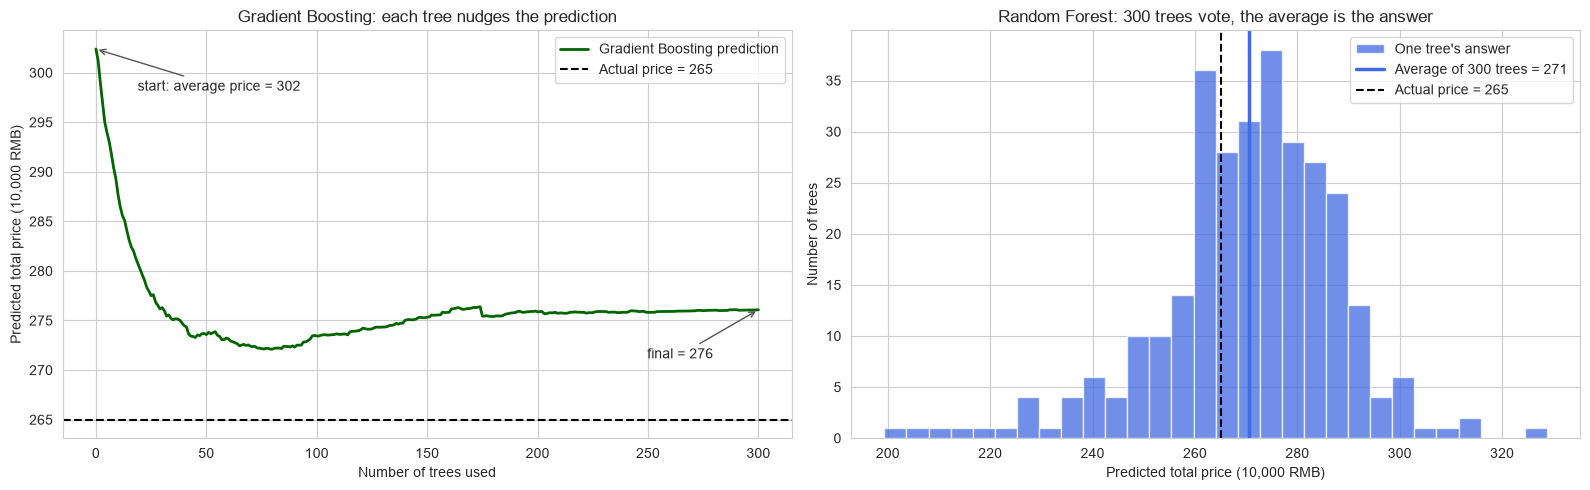

In [17]:
# ==============================================================================
# WALKTHROUGH 3b: How the ensembles build their prediction for the example house
# ==============================================================================
pos = X_test.index.get_loc(ex)
actual = r['total_price']

gb_steps = np.array([p[0] for p in gb_model.staged_predict(x_ex)])
gb_start = float(y_train.mean())
rf_votes = rf_tree_test[:, pos]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

ax = axes[0]
ax.plot(range(0, len(gb_steps) + 1), np.r_[gb_start, gb_steps], color='darkgreen', lw=2, label='Gradient Boosting prediction')
ax.axhline(actual, color='black', ls='--', lw=1.5, label=f'Actual price = {actual:.0f}')
ax.annotate(f'start: average price = {gb_start:.0f}', (0, gb_start), xytext=(30, -30),
            textcoords='offset points', arrowprops=dict(arrowstyle='->', color='#555'))
ax.annotate(f'final = {gb_steps[-1]:.0f}', (len(gb_steps), gb_steps[-1]), xytext=(-80, -35),
            textcoords='offset points', arrowprops=dict(arrowstyle='->', color='#555'))
ax.set_title('Gradient Boosting: each tree nudges the prediction')
ax.set_xlabel('Number of trees used')
ax.set_ylabel('Predicted total price (10,000 RMB)')
ax.legend(loc='best')

ax = axes[1]
ax.hist(rf_votes, bins=30, color='royalblue', alpha=0.75, edgecolor='white', label="One tree's answer")
ax.axvline(rf_votes.mean(), color='royalblue', lw=2.5, label=f'Average of 300 trees = {rf_votes.mean():.0f}')
ax.axvline(actual, color='black', ls='--', lw=1.5, label=f'Actual price = {actual:.0f}')
ax.set_title('Random Forest: 300 trees vote, the average is the answer')
ax.set_xlabel('Predicted total price (10,000 RMB)')
ax.set_ylabel('Number of trees')
ax.legend()

plt.tight_layout()
plt.show()

### 3c. Predictions for 10 random test houses

In [18]:
# ==============================================================================
# WALKTHROUGH 3c: Actual vs. predicted for 10 houses the models never saw
# ==============================================================================
rng = np.random.default_rng(7)
sample_pos = rng.choice(len(X_test), size=10, replace=False)
sample_idx = X_test.index[sample_pos]

table = df_clean.loc[sample_idx, ['district', 'area', 'rooms', 'decoration', 'total_price']].copy()
table.columns = ['District', 'Area (sqm)', 'Rooms', 'Decoration', 'Actual']
for name, short in [('Decision Tree (Baseline)', 'DT pred'), ('Random Forest (Upgraded)', 'RF pred'), ('Gradient Boosting (Upgraded)', 'GB pred')]:
    table[short] = predictions[name][sample_pos].round(0)
table['GB error %'] = ((table['GB pred'] - table['Actual']) / table['Actual'] * 100).round(1)
print('Prices in 10,000 RMB')
display(table.reset_index(drop=True))

Prices in 10,000 RMB


,District,Area (sqm),Rooms,Decoration,Actual,DT pred,RF pred,GB pred,GB error %
0,Pukou,87.73,3.0,Other,205.0,204.0,205.0,203.0,-1.0
1,Pukou,119.55,3.0,Refined,258.0,234.0,241.0,247.0,-4.3
2,Jiangning,171.72,3.0,Roughcast,380.0,589.0,531.0,468.0,23.2
3,Gulou,45.57,2.0,Other,158.0,134.0,159.0,164.0,3.8
4,Xuanwu,65.00,2.0,Other,228.0,198.0,195.0,193.0,-15.4
5,Gulou,176.70,4.0,Other,1130.0,846.0,864.0,905.0,-19.9
6,Jiangning,68.81,2.0,Other,213.0,193.0,189.0,192.0,-9.9
7,Gulou,31.43,1.0,Other,118.0,110.0,110.0,110.0,-6.8
8,Jiangning,87.20,3.0,Other,228.0,227.0,237.0,228.0,0.0
9,Qinhuai,63.15,2.0,Other,201.0,171.0,172.0,170.0,-15.4


### 3d. Try it yourself: predict a new house
Change the values in the last lines and re-run the cell.

In [19]:
# ==============================================================================
# WALKTHROUGH 3d: Predict the price of ANY house you describe
# ==============================================================================
def predict_house(area, rooms, halls, baths, district, total_floors=18, floor_tier='Mid',
                  decoration='Refined', building_type='Slab', elevator='Yes',
                  tenure='Over_5_Yrs', structure='Steel_Concrete', south=True,
                  years_since_last_tx=-1, compound=None):
    # Build the feature row exactly like the training data
    row = {
        'area': area, 'rooms': rooms, 'halls': halls, 'baths': baths, 'total_floors': total_floors,
        'area_per_room': area / (rooms + 1), 'total_rooms': rooms + halls + baths,
        'is_south': int(south), 'years_since_last_tx': years_since_last_tx,
    }
    for col, val in [('district', district), ('decoration', decoration), ('building_type', building_type),
                     ('elevator', elevator), ('floor_tier', floor_tier), ('tenure', tenure), ('structure', structure)]:
        row[f'{col}_{val}'] = 1
    x = pd.DataFrame([row]).reindex(columns=X_train.columns, fill_value=0).astype(float)
    # Price per sqm of the compound (learned from training data).
    # Unknown / no compound → use the average price per sqm of the DISTRICT instead.
    if compound in comm_encoded_map.index:
        est = comm_encoded_map[compound]
    else:
        est = district_unit_mean.get(district, global_unit_mean)
    x['compound_est_unit_price'] = est
    x['compound_baseline_total'] = est * area / 10000.0

    print(f"House: {district}, {area} sqm, {rooms} rooms / {halls} halls / {baths} baths, {decoration}"
          + (f", compound '{compound}'" if compound else '') + f"  (est. {est:,.0f} RMB/sqm)")
    for name, model in models.items():
        print(f"  {name:<30} → {model.predict(x)[0]:7.1f}  (10,000 RMB)")

district_unit_mean = train_subset.groupby('district')['unit_price'].mean()

# Districts you can use: Jiangning, Gulou, Qinhuai, Pukou, Jianye, Xuanwu, Qixia, Yuhuatai
predict_house(area=90, rooms=3, halls=2, baths=1, district='Gulou')
print()
predict_house(area=90, rooms=3, halls=2, baths=1, district='Pukou')
print()
predict_house(area=140, rooms=4, halls=2, baths=2, district='Jianye', decoration='Refined')

House: Gulou, 90 sqm, 3 rooms / 2 halls / 1 baths, Refined  (est. 39,642 RMB/sqm)
  Decision Tree (Baseline)       →   414.1  (10,000 RMB)
  Random Forest (Upgraded)       →   425.2  (10,000 RMB)
  Gradient Boosting (Upgraded)   →   414.5  (10,000 RMB)

House: Pukou, 90 sqm, 3 rooms / 2 halls / 1 baths, Refined  (est. 23,411 RMB/sqm)
  Decision Tree (Baseline)       →   195.5  (10,000 RMB)
  Random Forest (Upgraded)       →   204.8  (10,000 RMB)
  Gradient Boosting (Upgraded)   →   201.6  (10,000 RMB)

House: Jianye, 140 sqm, 4 rooms / 2 halls / 2 baths, Refined  (est. 39,874 RMB/sqm)
  Decision Tree (Baseline)       →   700.2  (10,000 RMB)
  Random Forest (Upgraded)       →   659.5  (10,000 RMB)
  Gradient Boosting (Upgraded)   →   672.2  (10,000 RMB)


# Interactive app (Gradio)

1. Run the cell below. It saves the trained models and data to `model_artifacts.joblib`.
2. Start the app from a terminal in this folder:
   ```
   myenv\Scripts\python app.py
   ```
   Your browser opens at http://127.0.0.1:7860. It has three tabs: **Predict** (with 🎲 random houses), **Explore data** and **Model performance**.

In [20]:
# ==============================================================================
# GRADIO: Save everything the app needs
# ==============================================================================
import joblib

district_unit_mean = train_subset.groupby('district')['unit_price'].mean()

app_cols = ['id', '小区名称', 'district', 'total_price', 'unit_price', 'area', 'rooms', 'halls', 'baths',
            'total_floors', 'floor_tier', 'decoration', 'building_type', 'elevator', 'tenure',
            'structure', 'is_south', 'years_since_last_tx']
app_data = df_clean[app_cols].copy()
app_data['is_test'] = app_data.index.isin(idx_test)

joblib.dump({
    'models': models,
    'feature_cols': list(X_train.columns),
    'comm_encoded_map': comm_encoded_map,
    'global_unit_mean': global_unit_mean,
    'district_unit_mean': district_unit_mean,
    'data': app_data,
    'y_test': y_test.to_numpy(),
    'predictions': predictions,
    'comparison_df': comparison_df,
}, 'model_artifacts.joblib', compress=3)

print(f"Saved model_artifacts.joblib ({os.path.getsize('model_artifacts.joblib') / 1e6:.1f} MB)")
print("Now run in a terminal:  myenv\\Scripts\\python app.py")

Saved model_artifacts.joblib (30.3 MB)
Now run in a terminal:  myenv\Scripts\python app.py
